/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Loan Approval Prediction Model Comparison:

LogisticRegression:
Accuracy=0.50
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


RidgeClassifier:
Accuracy=1.00
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2


RandomForest:
Accuracy=0.50
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.50      

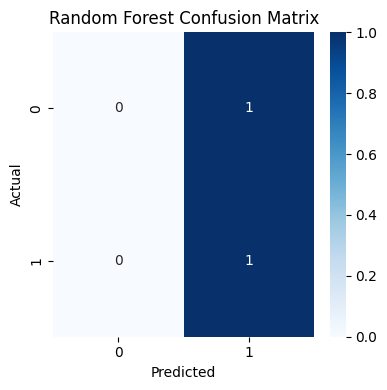

/tmp/ipython-input-348145694.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_names, y=importances, palette='viridis')


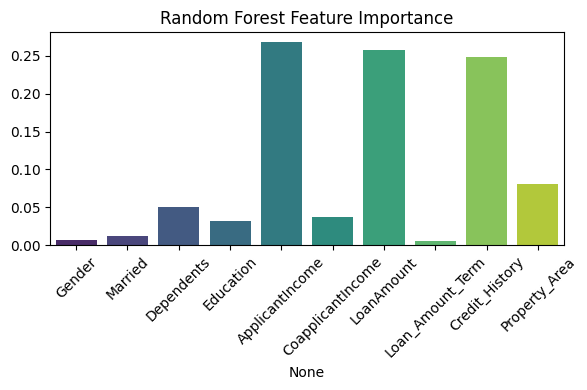


Prediction for new applicant: Approved


In [1]:
# Loan Approval Prediction Using Machine Learning

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sample synthetic loan data (replace with actual for full runs)
data = pd.DataFrame({
    'Gender': [1, 0, 1, 0, 1, 1, 0, 1, 0, 1],  # 1=Male, 0=Female
    'Married': [1, 1, 0, 1, 0, 1, 0, 1, 1, 0], # 1=Yes, 0=No
    'Dependents': [0, 2, 1, 0, 0, 3, 2, 1, 0, 1],
    'Education': [0, 1, 1, 0, 1, 1, 0, 0, 1, 0], # 0=Graduate, 1=Not Graduate
    'ApplicantIncome': [5000, 4000, 2500, 3500, 6000, 4200, 2200, 7000, 4000, 3200],
    'CoapplicantIncome': [0, 1500, 1800, 2100, 0, 1400, 1700, 2000, 1500, 1650],
    'LoanAmount': [200, 150, 100, 120, 300, 130, 110, 250, 180, 115],
    'Loan_Amount_Term': [360, 180, 360, 180, 360, 180, 360, 360, 180, 360],
    'Credit_History': [1, 0, 1, 1, 0, 1, 1, 0, 1, 1],
    'Property_Area': [0, 2, 1, 0, 1, 2, 0, 1, 0, 2], # 0=Urban, 1=Semiurban, 2=Rural
    'Loan_Status': [1, 0, 1, 1, 0, 1, 1, 0, 1, 1]    # 1=Approved, 0=Rejected
})

# 2. Features and target
X = data.drop(['Loan_Status'], axis=1)
y = data['Loan_Status']

# 3. Preprocessing: Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# 5. Model definitions, fitting, and predictions
models = {
    'LogisticRegression': LogisticRegression(max_iter=200),
    'RidgeClassifier': RidgeClassifier(),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42)
}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'ConfusionMatrix': confusion_matrix(y_test, y_pred),
        'Report': classification_report(y_test, y_pred)
    }

# 6. Print model performance
print("Loan Approval Prediction Model Comparison:")
for name, metrics in results.items():
    print(f"\n{name}:\nAccuracy={metrics['Accuracy']:.2f}\nClassification Report:\n{metrics['Report']}")

# 7. Visualize confusion matrix for best model (Random Forest)
cm = results['RandomForest']['ConfusionMatrix']
plt.figure(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()

# 8. Feature importance for Random Forest
rf_model = models['RandomForest']
importances = rf_model.feature_importances_
feat_names = X.columns
plt.figure(figsize=(6,4))
sns.barplot(x=feat_names, y=importances, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9. Demo prediction for new loan application
new_app = pd.DataFrame([{
    'Gender': 1,
    'Married': 1,
    'Dependents': 0,
    'Education': 0,
    'ApplicantIncome': 6500,
    'CoapplicantIncome': 2000,
    'LoanAmount': 220,
    'Loan_Amount_Term': 360,
    'Credit_History': 1,
    'Property_Area': 1
}])
scaled_app = scaler.transform(new_app)
pred = rf_model.predict(scaled_app)[0]
print(f"\nPrediction for new applicant: {'Approved' if pred==1 else 'Rejected'}")
